# 7. Tadakhul

The tail of a letter leaves the baseline, goes down, and continues below the
word. The letters above the tail move up.

A font cannot supply this stroke, because its length depends on the text after
the letter. `Tadakhul` is a glyph rule. It operates after textsynth shapes the
line, when the widths are known.

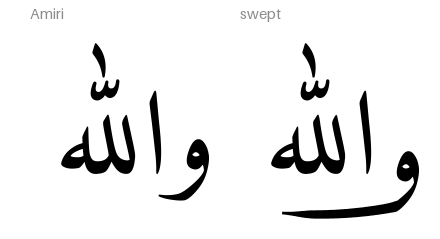

In [1]:
from textsynth import (
    Font,
    Layout,
    SweepShape,
    Synthesizer,
    TadakhulMerged,
    TadakhulQuantised,
    TadakhulScaled,
)
from nbutil import FONT, columns, sheet

TEXT = "والله"
LONGER = "وروده الى المدينة"
layout = Layout(size=120, padding=20, supersample=2)

columns(
    [
        (
            "",
            Synthesizer(font=FONT, layout=layout)(TEXT),
            Synthesizer(font=FONT, layout=layout, glyph_rules=[TadakhulMerged(letters="و", length=4)])(TEXT),
        )
    ],
    headings=("Amiri", "swept"),
    gutter=20,
)

## The length is counted in letters

`length=2` makes the letter as long as the two letters after it. A word can
carry several short sweeps.

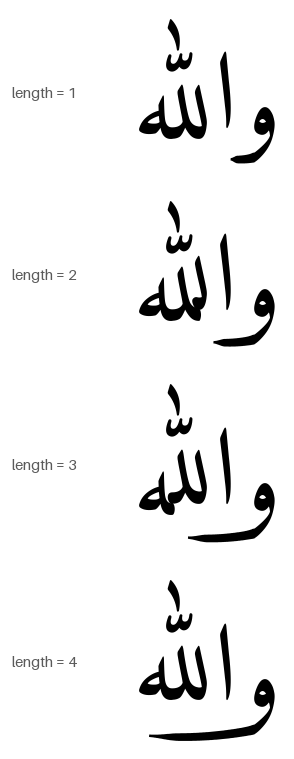

In [2]:
sheet(
    [
        (
            f"length = {n}",
            Synthesizer(
                font=FONT,
                layout=Layout(size=110, padding=18, supersample=2),
                glyph_rules=[TadakhulMerged(letters="و", length=n)],
            )(TEXT),
        )
        for n in range(1, 5)
    ],
    gutter=120,
)

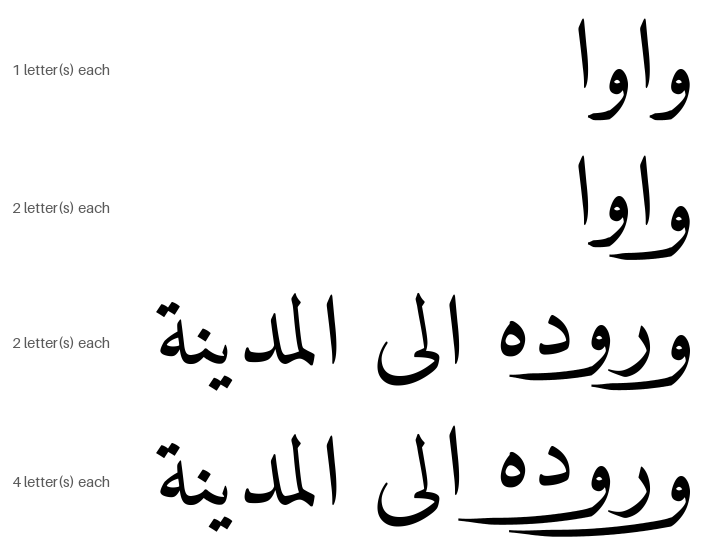

In [3]:
rows = []
for text, length in (("واوا", 1), ("واوا", 2), (LONGER, 2), (LONGER, 4)):
    rows.append((
        f"{length} letter(s) each",
        Synthesizer(
            font=FONT,
            layout=Layout(size=100, padding=16, supersample=2),
            glyph_rules=[TadakhulMerged(letters="و", length=length)],
        )(text),
    ))
sheet(rows, gutter=140)

## The sweep is the letter's own stroke

`cut_terminal` finds the end of the stroke. It takes the extreme point in the
direction of travel. Then it walks the two edges back and tests that they stay
parallel. `continue_stroke` closes the cut with the sweep. The letter and the
sweep come out as one contour.

In [4]:
from textsynth.outlines import body_path, cut_terminal, glyph_contours, measure_end

font = Font(FONT)
glyph_set = font.ttfont().getGlyphSet()
path = body_path(glyph_contours(glyph_set, "uni0648"))  # waw
cut = cut_terminal(path, 0.26 * font.upem)
end = measure_end(cut, max_height=-0.05 * font.upem)

print(f"cut across the stroke at {cut.centre[0]:.0f}, {cut.centre[1]:.0f} font units")
print(f"stroke width there: {cut.width:.0f} units ({cut.width / font.upem:.3f} em)")
print(f"heading at the cut: {end.heading * 180 / 3.14159:.0f} degrees")
print(f"curvature at the cut: {end.curvature:.5f} per unit")
print(f"nib fitted from the letter: {end.nib.angle * 180 / 3.14159:.0f} degrees")

cut across the stroke at 155, -167 font units
stroke width there: 90 units (0.090 em)
heading at the cut: -159 degrees
curvature at the cut: -0.00559 per unit
nib fitted from the letter: 158 degrees


## The path is a motion

`SweepShape` gives the path as a curvature profile. The profile starts at the
curvature of the cut and opens out.

```
k(s) = k0 * exp(-s / ease) + arc
```

`belly` sets where the sweep is at its lowest point. The depth follows from
the length of the sweep. `max_depth` is only a limit.

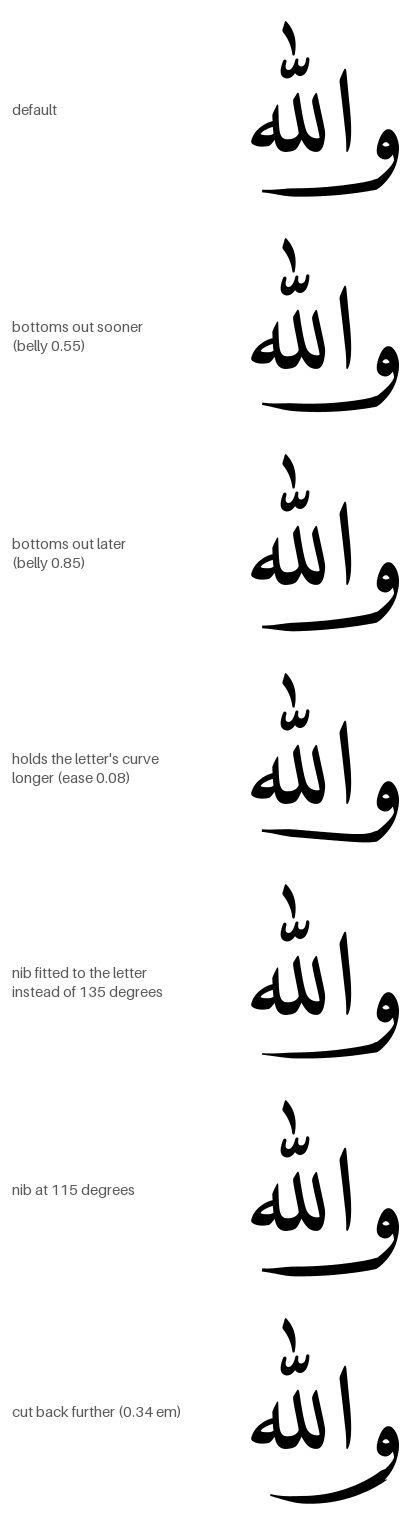

In [5]:
rows = []
for name, shape in (
    ("default", SweepShape()),
    ("bottoms out sooner\n(belly 0.55)", SweepShape(belly=0.55)),
    ("bottoms out later\n(belly 0.85)", SweepShape(belly=0.85)),
    ("holds the letter's curve\nlonger (ease 0.08)", SweepShape(ease=0.08)),
    ("nib fitted to the letter\ninstead of 135 degrees", SweepShape(nib_angle=None)),
    ("nib at 115 degrees", SweepShape(nib_angle=115)),
    ("cut back further (0.34 em)", SweepShape(cut_back=0.34)),
):
    rows.append((
        name,
        Synthesizer(font=FONT, layout=layout, glyph_rules=[TadakhulMerged(letters="و", length=4, shape=shape)])(TEXT),
    ))
sheet(rows, gutter=230)

## The width comes from the nib

The nib stays at one angle for the full stroke. Its size makes the first
stroke of the sweep as thick as the letter at the cut. `lift` decreases the
width at the end.

`nib_angle=None` fits the nib to the letter's own stroke. The fit needs a part
of the stroke at full width.

In [6]:
from textsynth.outlines import fit_nib, tail_skeleton
import math

for name, glyph in (("ra", "uni0631"), ("waw", "uni0648")):
    p = body_path(glyph_contours(glyph_set, glyph))
    c = cut_terminal(p, 0.26 * font.upem)
    nib = fit_nib(tail_skeleton(c))
    print(f"{name:>4}: fitted nib angle {math.degrees(nib.angle):.0f} degrees, width {nib.width / font.upem:.3f} em")
print("\nclassical rhombic-dot angle: 135 degrees")

  ra: fitted nib angle 145 degrees, width 0.102 em
 waw: fitted nib angle 158 degrees, width 0.117 em

classical rhombic-dot angle: 135 degrees


## Which letters can sweep

A sweep needs a free terminal, below the baseline, in the direction of the
sweep. Amiri has seven such letters. The other letters have a join, a curve,
or a terminal on the baseline.

In [7]:
from textsynth.shaping import shape as shape_text
from textsynth.sweeps import SWEEPERS, SweptGlyph, free_after

ALPHABET = "ابتثجحخدذرزسشصضطظعغفقكلمنهوىءةپچژگکیڤڠڽݢۏھڭؤڑۆے"

sweeps, refused = [], []
for letter in dict.fromkeys(ALPHABET):
    if not font.covers(letter):
        continue
    text = "سم" + letter + ("ادب" if free_after("سم" + letter + "ا", 2) else " ادب")
    glyphs = [g for g in shape_text(text, font) if g.cluster == 2]
    end = (
        SweptGlyph(font=font, glyph=glyphs[0].name, shape=SweepShape()).end if glyphs and free_after(text, 2) else None
    )
    (sweeps if end is not None else refused).append(letter)

print("can sweep:", " ".join(sweeps))
print("refused:  ", " ".join(refused))
print("\nSWEEPERS default:", SWEEPERS)

can sweep: ر ز و ژ ۏ ؤ ڑ ۆ
refused:   ا ب ت ث ج ح خ د ذ س ش ص ض ط ظ ع غ ف ق ك ل م ن ه ى ء ة پ چ گ ک ی ڤ ڠ ڽ ݢ ھ ڭ ے

SWEEPERS default: ورزژۏؤڑۆ


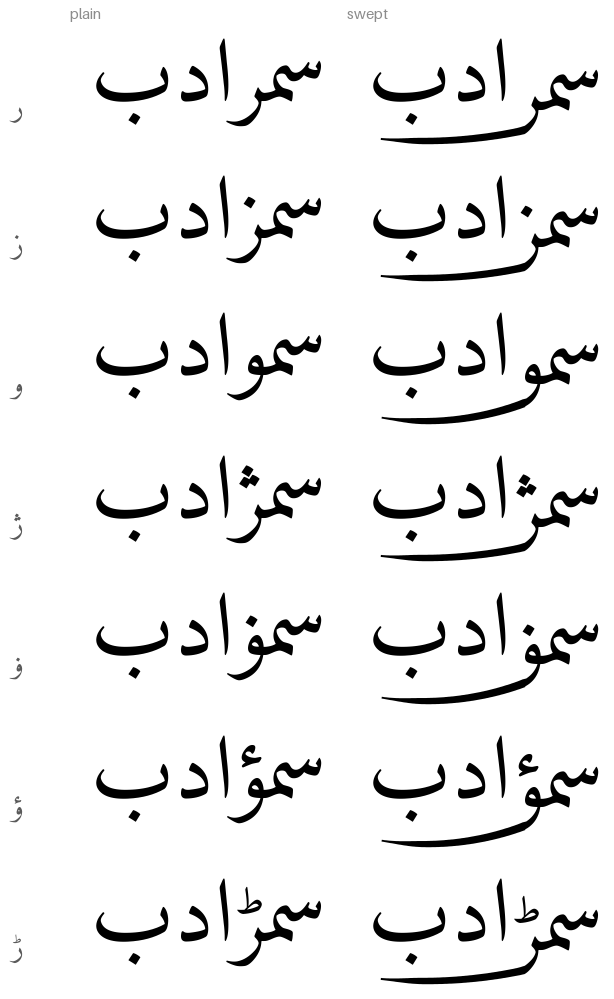

In [8]:
small = Layout(size=90, padding=14, supersample=2)
rows = []
for letter in sweeps:
    text = "سم" + letter + ("ادب" if free_after("سم" + letter + "ا", 2) else " ادب")
    rows.append((
        letter,
        Synthesizer(font=FONT, layout=small)(text),
        Synthesizer(font=FONT, layout=small, glyph_rules=[TadakhulMerged(letters=letter, length=3)])(text),
    ))
from nbutil import label_font

columns(rows, headings=("plain", "swept"), gutter=60, font=label_font(30, arabic=True))

## Three ways to make the same geometry

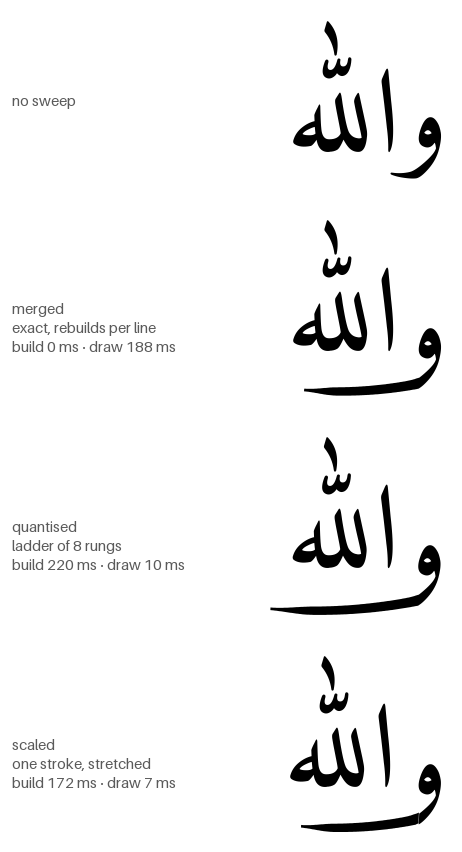

In [9]:
import time


def timed(synth, text):
    start = time.perf_counter()
    synth.patched_font  # force the patch, so it is not timed as drawing
    build = time.perf_counter() - start
    start = time.perf_counter()
    image = synth(text)
    return image, build * 1000, (time.perf_counter() - start) * 1000


rows = [("no sweep", Synthesizer(font=FONT, layout=layout)(TEXT))]
for name, rule in (
    ("merged\nexact, rebuilds per line", TadakhulMerged(letters="و", length=4)),
    ("quantised\nladder of 8 rungs", TadakhulQuantised(letters="و", length=4)),
    ("scaled\none stroke, stretched", TadakhulScaled(letters="و", length=4)),
):
    image, build, draw = timed(Synthesizer(font=FONT, layout=layout, glyph_rules=[rule]), TEXT)
    rows.append((f"{name}\nbuild {build:.0f} ms · draw {draw:.0f} ms", image))
sheet(rows, gutter=250)

| rule | font build | for each line | length |
| --- | --- | --- | --- |
| `TadakhulMerged` | for each line | slow | exact |
| `TadakhulQuantised` | one time | fast | nearest of N steps |
| `TadakhulScaled` | one time | fast | exact |

Use `TadakhulQuantised` for bulk work. Use `TadakhulMerged` for one image.

## The letters above a sweep move up

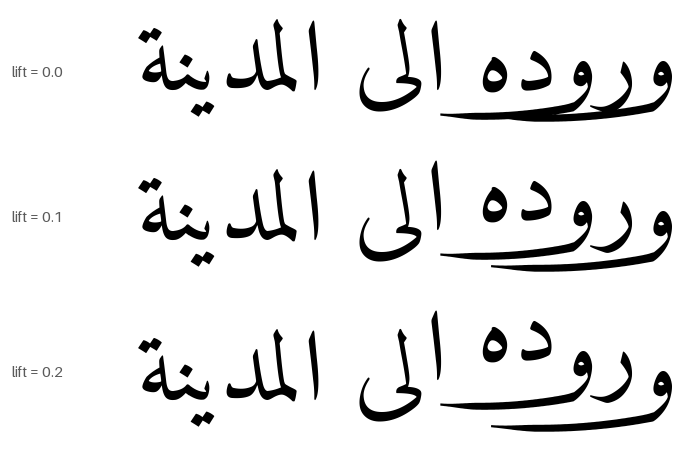

In [10]:
rows = []
for lift in (0.0, 0.10, 0.20):
    rows.append((
        f"lift = {lift}",
        Synthesizer(
            font=FONT,
            layout=Layout(size=100, padding=18, supersample=2),
            glyph_rules=[TadakhulMerged(letters="و", length=4, lift=lift)],
        )(LONGER),
    ))
sheet(rows, gutter=120)

## Limits

- Amiri's waw is level at the end of its tail. A faithful sweep is then flat.
  The depth comes from `belly`.
- `TadakhulScaled` keeps the letter and the sweep as two glyphs.
- Each letter above a sweep moves up by the same amount.
- A sweep below a ligature reaches below all of it.
- `SWEEPERS` is correct for Amiri only. Run `examples/other_fonts.py` for
  another font.